In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
loan_data = pd.read_csv("loan_approval_data.csv")
loan_data.duplicated().sum()

np.int64(0)

# handling missing values


In [3]:
categorical_cols = loan_data.select_dtypes(include=["object","string"]).columns
numerical_cols = loan_data.select_dtypes(include=["number"]).columns

In [4]:
categorical_cols 

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='str')

In [5]:
numerical_cols

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='str')

In [6]:
# removing null values with sklearn lib
from sklearn.impute import SimpleImputer
num_imp = SimpleImputer(strategy="mean")
loan_data[numerical_cols] = num_imp.fit_transform(loan_data[numerical_cols])

cat_imp =  SimpleImputer(strategy="most_frequent")
loan_data[categorical_cols] = cat_imp.fit_transform(loan_data[categorical_cols])


In [7]:
loan_data.isnull().sum()

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

# EDA 

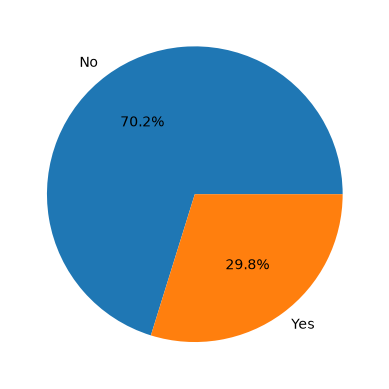

In [8]:
# is data balanced or not ---> pie plot
classes_count = loan_data["Loan_Approved"].value_counts()
# print(classes_count)
# without oops
# plt.pie(classes_count, labels=["No","Yes"], autopct="%1.1f%%")

# with oops
fig, ax = plt.subplots()
ax.pie(classes_count, labels=["No","Yes"], autopct="%1.1f%%")

Gender
Male      621
Female    379
Name: count, dtype: int64


<Axes: xlabel='Gender', ylabel='count'>

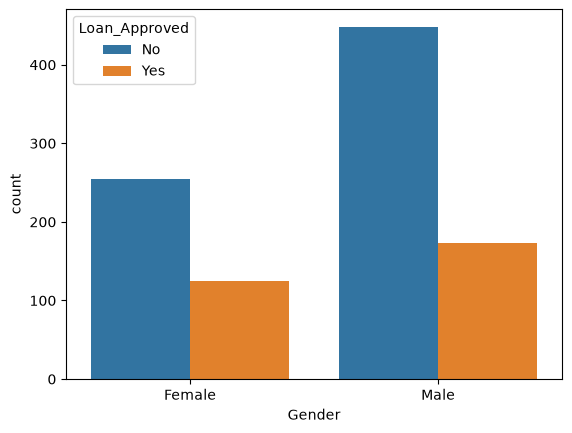

In [9]:
# analyzing each category --> Gender
gender_cnt = loan_data["Gender"].value_counts()
print(gender_cnt)
sns.countplot(loan_data, x="Gender", hue = "Loan_Approved")

Education_Level
Graduate        722
Not Graduate    278
Name: count, dtype: int64


<Axes: xlabel='Education_Level', ylabel='count'>

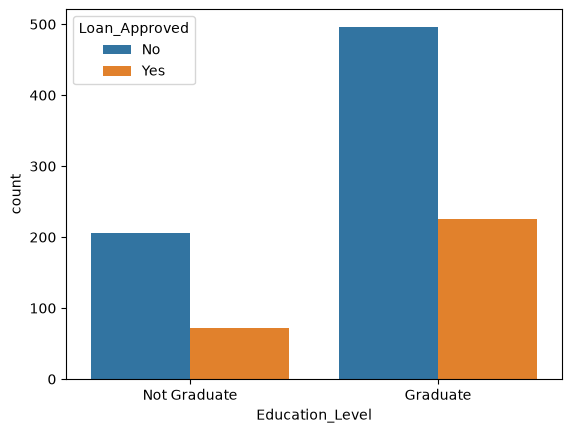

In [10]:
# Education_Level
edu_cnt = loan_data["Education_Level"].value_counts()
print(edu_cnt)
sns.countplot(loan_data, x="Education_Level", hue="Loan_Approved")

Loan_Purpose
Business     252
Car          199
Home         190
Education    181
Personal     178
Name: count, dtype: int64


<Axes: xlabel='Loan_Purpose', ylabel='count'>

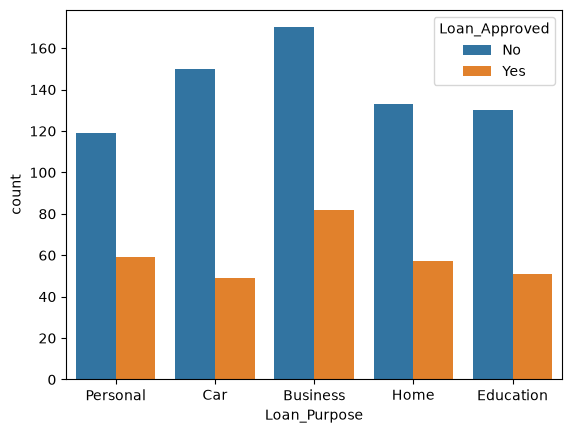

In [11]:
# loan purpose
pur_cnt = loan_data["Loan_Purpose"].value_counts()
print(pur_cnt)
sns.countplot(loan_data, x="Loan_Purpose", hue="Loan_Approved")

<Axes: xlabel='Applicant_Income', ylabel='Count'>

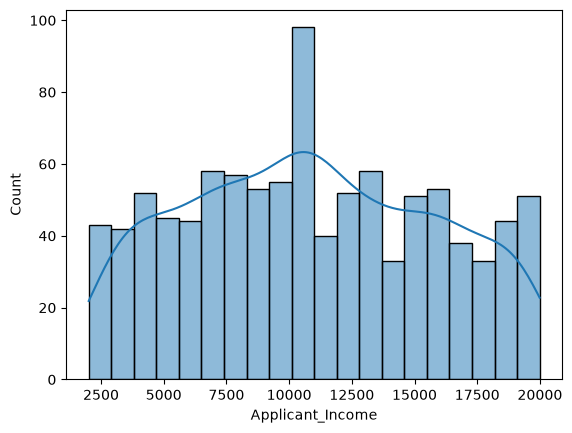

In [12]:
# analyze income
sns.histplot(
    loan_data,
    x="Applicant_Income",
    bins=20,
    kde=True
)

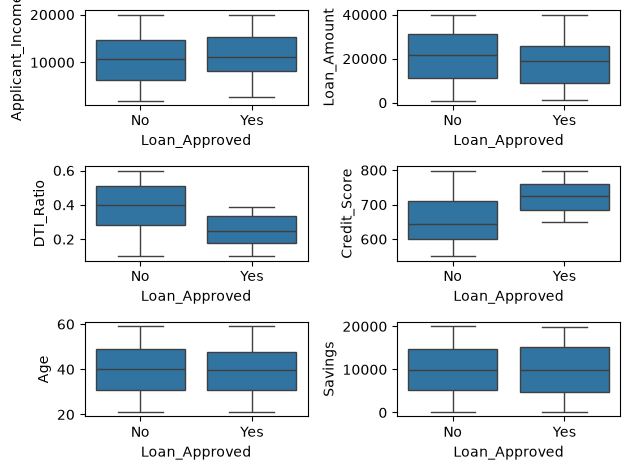

In [13]:
# outliers --> box plot
fig, ax = plt.subplots(3,2)
sns.boxplot(ax = ax[0, 0], data=loan_data, x="Loan_Approved", y="Applicant_Income")
sns.boxplot(ax = ax[0, 1], data=loan_data, x="Loan_Approved", y="Loan_Amount")
sns.boxplot(ax = ax[1, 0], data=loan_data, x="Loan_Approved", y="DTI_Ratio")
sns.boxplot(ax = ax[1, 1], data=loan_data, x="Loan_Approved", y="Credit_Score")
sns.boxplot(ax = ax[2, 0], data=loan_data, x="Loan_Approved", y="Age")
sns.boxplot(ax = ax[2, 1], data=loan_data, x="Loan_Approved", y="Savings")
plt.tight_layout()

<Axes: xlabel='Credit_Score', ylabel='Count'>

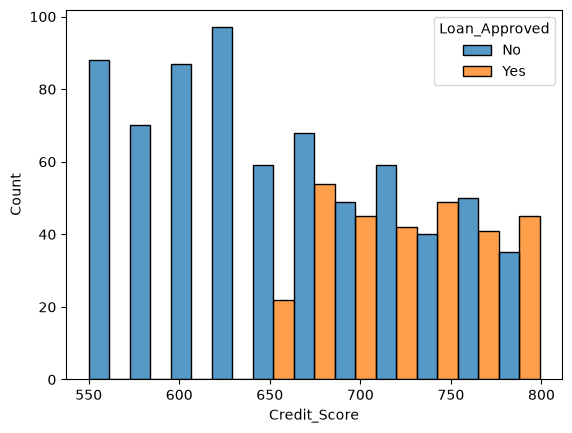

In [14]:
# credit score with loan approved
sns.histplot(
    data=loan_data,
    x="Credit_Score",
    hue="Loan_Approved",
    multiple="dodge"
)

In [15]:
# droping applicant id
# loan_data = loan_data.drop(columns=["Applicant_ID"])
loan_data.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


In [25]:
# feature encoding
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
le = LabelEncoder()
loan_data["Loan_Approved"] = le.fit_transform(loan_data["Loan_Approved"])
loan_data["Education_Level"] = le.fit_transform(loan_data["Education_Level"]) 


In [32]:
for col in cols:
    if col not in loan_data.columns:
        print(col)

Employment_Status
Marital_Status
Loan_Purpose
Property_Area
Gender
Employer_Category


In [21]:
print(loan_data.columns.tolist())

['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Education_Level', 'Loan_Approved', 'Employment_Status_Salaried', 'Employment_Status_Self-employed', 'Employment_Status_Unemployed', 'Marital_Status_Single', 'Loan_Purpose_Car', 'Loan_Purpose_Education', 'Loan_Purpose_Home', 'Loan_Purpose_Personal', 'Property_Area_Semiurban', 'Property_Area_Urban', 'Gender_Male', 'Employer_Category_Government', 'Employer_Category_MNC', 'Employer_Category_Private', 'Employer_Category_Unemployed']


In [27]:
# one hot encoding
cols = ["Employment_Status", "Marital_Status", "Loan_Purpose", "Property_Area", "Gender", "Employer_Category"]

ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")

encoded = ohe.fit_transform(loan_data[cols])

encoded_df = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(cols), index=loan_data.index)

loan_data = pd.concat([loan_data.drop(columns=cols), encoded_df], axis=1)

In [ ]:
loan_data.columns

In [ ]:
print(encoded)

# heatmap corelation

<Axes: >

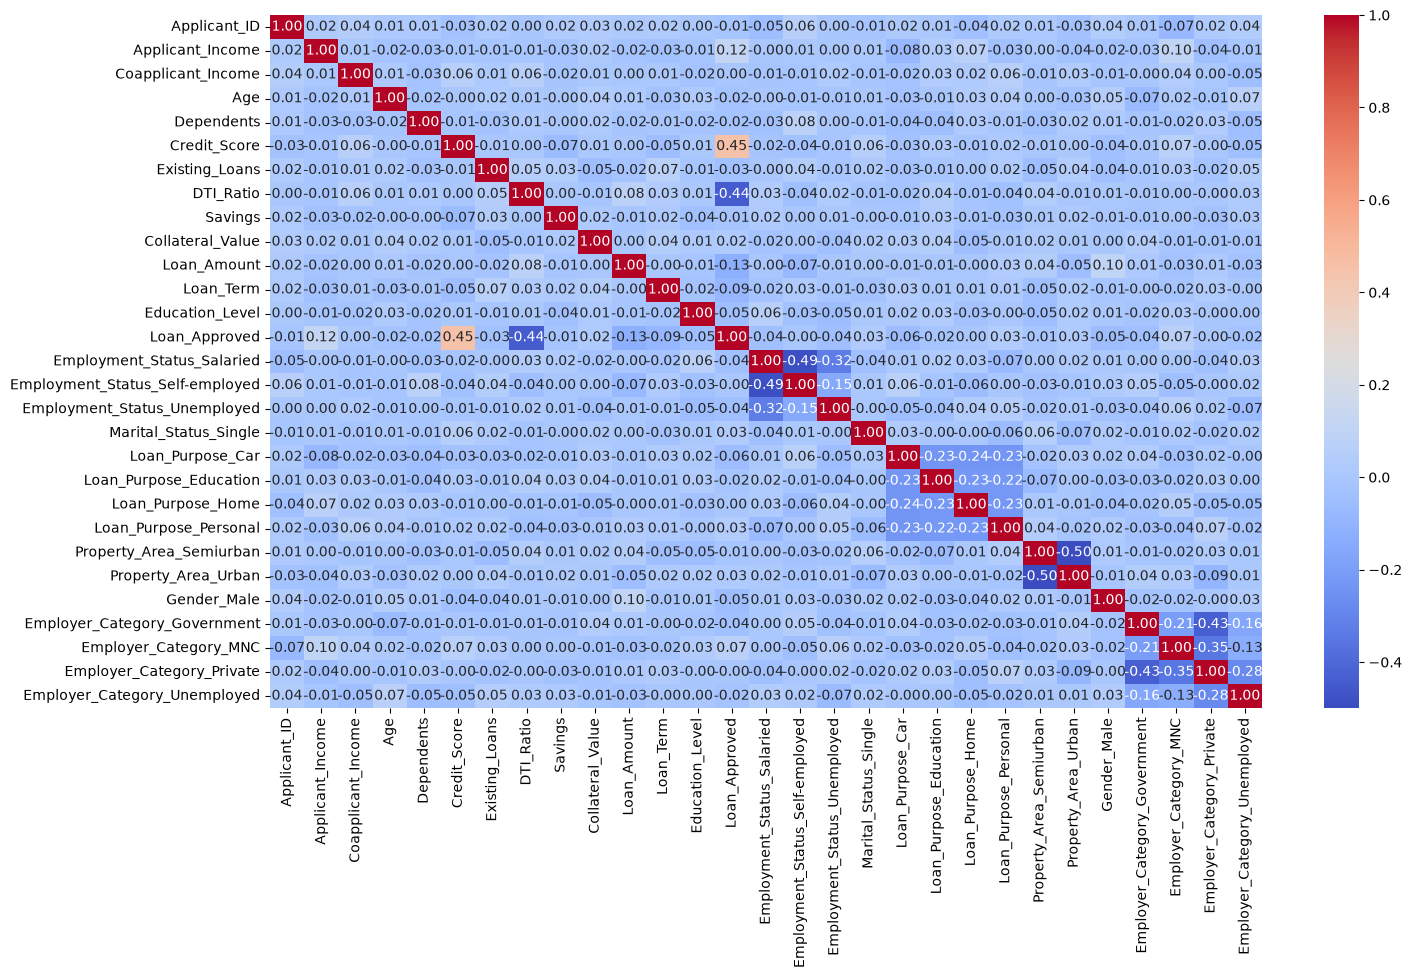

In [28]:
num_cols = loan_data.select_dtypes(include="number")
corr_matrix = num_cols.corr()

plt.figure(figsize=(16,9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

# feature scaling

In [29]:
X = loan_data.drop("Loan_Approved", axis=1)
y = loan_data["Loan_Approved"]
X_train,  X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## training the model

In [38]:
# logistic regression
from sklearn.linear_model import LogisticRegression 
model = LogisticRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

# evaluation
from sklearn.metrics import precision_score, accuracy_score, recall_score, confusion_matrix
print("Logistic Regression", precision_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))

print("Accuracy: ", accuracy_score(y_test, y_pred))
print("CM: ", confusion_matrix(y_test, y_pred))

Logistic Regression 0.7868852459016393
Precision:  0.7868852459016393
Recall:  0.7868852459016393
Accuracy:  0.87
CM:  [[126  13]
 [ 13  48]]


In [40]:
# KNN regression

from sklearn.neighbors import KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors=7)
knn_model.fit(X_train_scaled, y_train)
y_pred = knn_model.predict(X_test_scaled)

# evaluation
from sklearn.metrics import precision_score, accuracy_score, recall_score, confusion_matrix
print("precision score", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))

print("Accuracy: ", accuracy_score(y_test, y_pred))
print("CM: ", confusion_matrix(y_test, y_pred))

precision score 0.6428571428571429
Recall:  0.4426229508196721
Accuracy:  0.755
CM:  [[124  15]
 [ 34  27]]


In [42]:
# naive bayes
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

y_pred = nb_model.predict(X_test_scaled)

# Evaluation
print("Naive Bayes Model")
print("Precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))

print("Accuracy: ", accuracy_score(y_test, y_pred))
print("CM: ", confusion_matrix(y_test, y_pred))



Naive Bayes Model
Precision:  0.8035714285714286
Recall:  0.7377049180327869
Accuracy:  0.865
CM:  [[128  11]
 [ 16  45]]


# naive bayes was the best model till now

## feature engineering

In [49]:
loan_data["credit_score_sq"] = loan_data["Credit_Score"] ** 2
loan_data["DTI_ratio_sq"] = loan_data["DTI_Ratio"] ** 2

X = loan_data.drop(columns=["Loan_Approved", "Credit_Score", "DTI_Ratio"])
y = loan_data["Loan_Approved"]

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [50]:
# logistic regression
from sklearn.linear_model import LogisticRegression 
model = LogisticRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

# evaluation
from sklearn.metrics import precision_score, accuracy_score, recall_score, confusion_matrix
print("Logistic Regression", precision_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))

print("Accuracy: ", accuracy_score(y_test, y_pred))
print("CM: ", confusion_matrix(y_test, y_pred))

Logistic Regression 0.7903225806451613
Precision:  0.7903225806451613
Recall:  0.8032786885245902
Accuracy:  0.875
CM:  [[126  13]
 [ 12  49]]


In [51]:
# KNN regression

from sklearn.neighbors import KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors=7)
knn_model.fit(X_train_scaled, y_train)
y_pred = knn_model.predict(X_test_scaled)

# evaluation
from sklearn.metrics import precision_score, accuracy_score, recall_score, confusion_matrix
print("precision score", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))

print("Accuracy: ", accuracy_score(y_test, y_pred))
print("CM: ", confusion_matrix(y_test, y_pred))

precision score 0.6666666666666666
Recall:  0.45901639344262296
Accuracy:  0.765
CM:  [[125  14]
 [ 33  28]]


In [52]:
# naive bayes
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

y_pred = nb_model.predict(X_test_scaled)

# Evaluation
print("Naive Bayes Model")
print("Precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))

print("Accuracy: ", accuracy_score(y_test, y_pred))
print("CM: ", confusion_matrix(y_test, y_pred))

Naive Bayes Model
Precision:  0.7966101694915254
Recall:  0.7704918032786885
Accuracy:  0.87
CM:  [[127  12]
 [ 14  47]]
